# Análise do ensaio embarcado

Este notebook interpreta o log produzido por `notebooks/model_teste.ipynb`
em `results/ensaio/board_test.csv`. Ele não abre a serial nem executa o
firmware: lê o CSV, reconstrói a duração dos blocos artificiais e gera as
figuras e tabelas da análise.

Convenções:

- **gap artificial**: linhas com `gap=True`, criadas por `common.gaps` com
  duração de relógio conhecida. O PCA real continua disponível e serve de
  referência.
- **gap real**: ausência de linha por mais de 16 h entre leituras
  consecutivas. A série é quebrada nesses intervalos; a variação normal
  entre o fim de um dia e o começo do seguinte fica em 13 a 14 h.
- **tempo de inferência**: `inference_us`, medido no firmware ao redor de
  `runInference()` e gravado por amostra.

As figuras vão para `results/figuras/`; as tabelas, em CSV e Markdown, para
`results/ensaio/`. A cópia para `docs/figuras/` é manual.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# Raiz do repo: funciona com cwd em notebooks/ ou na raiz.
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "models" / "src").is_dir())
sys.path.insert(0, str(RAIZ / "models" / "src"))

from common import contract, gaps, paths, plots, results, server

for _s in (sys.stdout, sys.stderr):
    try:
        _s.reconfigure(encoding="utf-8", errors="replace")
    except (AttributeError, ValueError):
        pass

FREQ = "1h"
INV_DETALHE = "ifpee1"
INVERSORES = ("ifpee1", "ifpee2", "ifpee3")
GAPS_ENSAIO = ("6h", "6h", "24h", "24h", "3d", "15d")
LIMIAR_GAP_CURTO = pd.Timedelta(hours=6)
LIMIAR_NOITE = pd.Timedelta(hours=16)
LIMIAR_GAP_REAL = LIMIAR_NOITE
JANELA_MEDIA = pd.Timedelta(days=7)
AQUECIMENTO = 6
PREFIXO = "analise_"
SUBPASTA = "ensaio"
LIMITE_KW = 2.0
EXTENSO = (0.0, LIMITE_KW, 0.0, LIMITE_KW)


def salvar_csv(df, nome, subpasta):
    destino = paths.RESULTS / subpasta / f"{nome}.csv"
    destino.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(destino, index=False)
    print(f"  {destino.relative_to(paths.ROOT)}", flush=True)
    return destino


assert FREQ in contract.GRANULARIDADES, FREQ
plots.aplicar_estilo()
print(f"ensaio: {paths.ENSAIO / 'board_test.csv'}")

ensaio: C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\results\ensaio\board_test.csv


## Inventário do ensaio

In [2]:
ARQUIVO = paths.ENSAIO / "board_test.csv"
bruto = pd.read_csv(ARQUIVO, parse_dates=["sample"])

partes = []
for inv, d in bruto.groupby("inversor", sort=True):
    d = d.sort_values("sample").reset_index(drop=True)
    if d.empty:
        raise ValueError(f"{inv}: sem linhas no ensaio")
    if d["sample"].isna().any():
        raise ValueError(f"{inv}: sample com data nula")
    mask, rotulo = gaps.gerar_gaps(
        d, freq=FREQ, gaps=GAPS_ENSAIO, time_col="sample")
    if not np.array_equal(mask, d["gap"].to_numpy(bool)):
        raise AssertionError(
            f"{inv}: a coluna gap do CSV nao reproduz GAPS_ENSAIO; "
            "o ensaio e a analise estao com listas de gaps diferentes")
    d["gap_h"] = rotulo.astype(float)
    inicia = d["gap"] & ~d["gap"].shift(fill_value=False)
    d["bloco"] = np.where(d["gap"], inicia.cumsum(), 0).astype(int)
    partes.append(d)

ensaio = pd.concat(partes, ignore_index=True)
if tuple(sorted(ensaio["inversor"].unique())) != INVERSORES:
    print("ATENCAO: inversores no CSV:",
          tuple(sorted(ensaio["inversor"].unique())))

resumo_inv = (ensaio.groupby("inversor")
              .agg(linhas=("sample", "size"),
                   gaps=("gap", "sum"),
                   reais_nan=("real", lambda s: s.isna().sum())))
resumo_inv["blocos"] = (ensaio[ensaio["gap"]]
                        .groupby("inversor")["bloco"].nunique())
print(resumo_inv.to_string())

blocos_ifpee1 = (ensaio[(ensaio["inversor"] == INV_DETALHE) & ensaio["gap"]]
                 .groupby("bloco")
                 .agg(inicio=("sample", "min"),
                      fim_observado=("sample", "max"),
                      leituras=("sample", "size"),
                      duracao_h=("gap_h", "first"))
                 .reset_index())
blocos_ifpee1["fim_previsto"] = (
    blocos_ifpee1["inicio"]
    + pd.to_timedelta(blocos_ifpee1["duracao_h"], unit="h"))
print(blocos_ifpee1.to_string(index=False))

          linhas  gaps  reais_nan  blocos
inversor                                 
ifpee1      4042   222          3       6
ifpee2      4042   222          3       6
ifpee3      4042   222          3       6
 bloco              inicio       fim_observado  leituras  duracao_h        fim_previsto
     1 2025-01-31 06:00:00 2025-01-31 11:00:00         6        6.0 2025-01-31 12:00:00
     2 2025-06-04 15:00:00 2025-06-05 14:00:00        11       24.0 2025-06-05 15:00:00
     3 2025-08-22 15:00:00 2025-08-22 16:00:00         2       24.0 2025-08-23 15:00:00
     4 2025-09-08 12:00:00 2025-09-23 11:00:00       165      360.0 2025-09-23 12:00:00
     5 2025-10-15 15:00:00 2025-10-15 16:00:00         2        6.0 2025-10-15 21:00:00
     6 2025-11-11 08:00:00 2025-11-14 07:00:00        36       72.0 2025-11-14 08:00:00


## 1. Série temporal completa

A série usa somente `ifpee1`, para manter o gráfico legível. As linhas de
real e predito são mantidas contínuas na pausa noturna, em buracos menores
que 6 h e nos blocos artificiais. Elas quebram apenas nos buracos reais de
6 h ou mais que não sejam a noite; o gap real de 2025-08-22 16:00 a
2025-09-03 08:00, com 280 h, quebra a série. O detalhe pontilhado dentro dos
blocos artificiais fica no item 2.

A linha grossa é a média móvel de 7 dias; a linha fina e clara é a leitura
bruta. Os blocos artificiais aparecem sombreados no painel principal e na
faixa inferior de marcação; a faixa inferior é o que torna visíveis os
blocos curtos no eixo anual.

  results\ensaio\analise_gaps_reais.csv


             inicio                 fim  horas
2025-08-22 16:00:00 2025-09-03 08:00:00  280.0


  figura: results\figuras\analise_serie_ifpee1.png


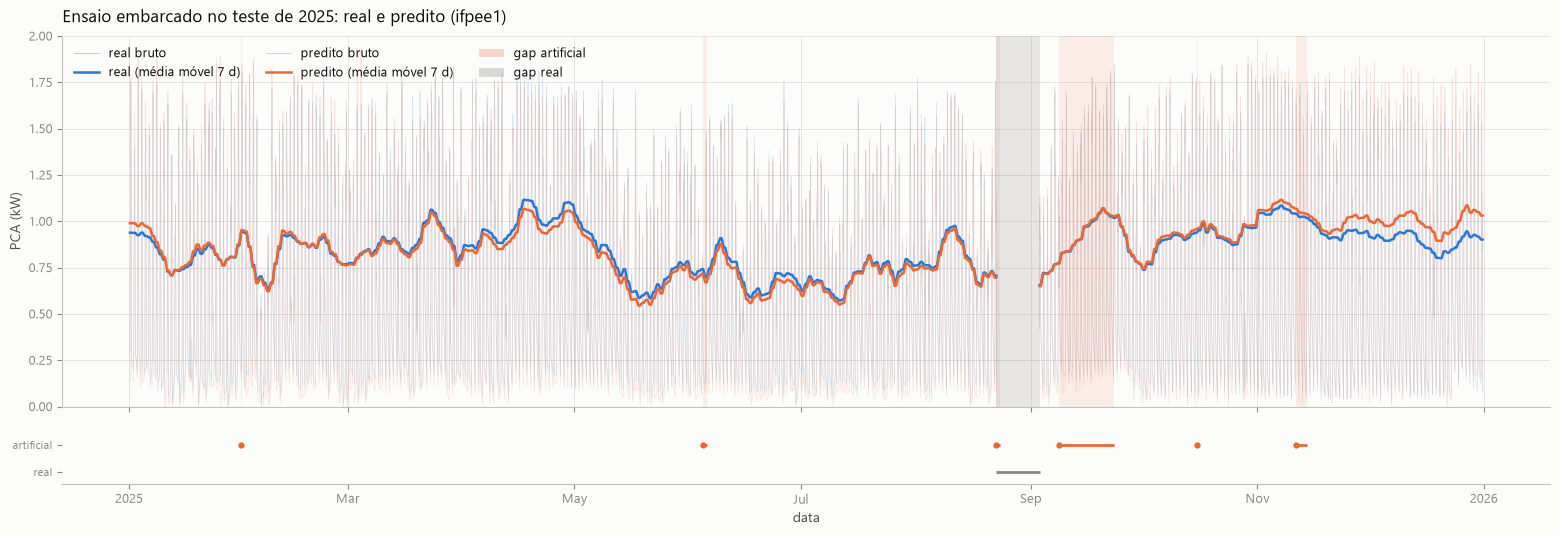

In [3]:
detalhe = (ensaio[ensaio["inversor"] == INV_DETALHE]
           .sort_values("sample").reset_index(drop=True))

dif = detalhe["sample"].diff()
cortes_reais = np.flatnonzero((dif > LIMIAR_GAP_REAL).to_numpy())
gaps_reais = pd.DataFrame([
    {"inicio": detalhe.loc[i - 1, "sample"],
     "fim": detalhe.loc[i, "sample"],
     "horas": dif.iloc[i] / pd.Timedelta(hours=1)}
    for i in cortes_reais
])
salvar_csv(gaps_reais, f"{PREFIXO}gaps_reais", SUBPASTA)
print(gaps_reais.to_string(index=False))

def plot_segmentada(ax, d, coluna, cor, janela):
    # Interpola a noite, os buracos com menos de 6 h e os blocos artificiais;
    # quebra nos buracos reais de 6 h ou mais que nao sejam a pausa noturna.
    dif = d["sample"].diff()
    noite = (d["sample"].dt.date.ne(d["sample"].shift().dt.date)
             & (dif <= LIMIAR_NOITE))
    quebra = (dif >= LIMIAR_GAP_CURTO) & ~noite
    bordas = np.r_[0, np.flatnonzero(quebra.to_numpy()), len(d)]
    for i in range(len(bordas) - 1):
        seg = d.iloc[bordas[i]:bordas[i + 1]]
        serie = seg.set_index("sample")[coluna]
        media = serie.rolling(janela, center=True, min_periods=1).mean()
        media = media.where(serie.notna())
        ax.plot(seg["sample"], seg[coluna], color=cor, lw=0.5,
                alpha=0.18, zorder=1)
        ax.plot(media.index, media.values, color=cor, lw=1.8, zorder=2)

fig, (ax, ax_faixa) = plt.subplots(
    2, 1, figsize=(16, 5.6), sharex=True,
    gridspec_kw={"height_ratios": [4.0, 0.65]})
plot_segmentada(ax, detalhe, "real", plots.REAL, JANELA_MEDIA)
plot_segmentada(ax, detalhe, "pred", plots.PREDITO, JANELA_MEDIA)

for _, b in blocos_ifpee1.iterrows():
    ax.axvspan(b["inicio"], b["fim_previsto"], color=plots.PREDITO,
               alpha=0.10, lw=0)
    ax_faixa.hlines(0.65, b["inicio"], b["fim_previsto"],
                    color=plots.PREDITO, lw=2.0)
    ax_faixa.plot(b["inicio"], 0.65, marker="o", ms=3.5,
                  color=plots.PREDITO, ls="none")
for _, g in gaps_reais.iterrows():
    ax.axvspan(g["inicio"], g["fim"], color=plots.MUDO,
               alpha=0.18, lw=0)
    ax_faixa.hlines(0.20, g["inicio"], g["fim"],
                    color=plots.MUDO, lw=2.0)

ax.set_ylim(0, LIMITE_KW)
plots.enfeitar(
    ax,
    f"Ensaio embarcado no teste de 2025: real e predito ({INV_DETALHE})",
    "", "PCA (kW)")
rotulo_media = f"média móvel {JANELA_MEDIA / pd.Timedelta(days=1):g} d"
handles = [
    plt.Line2D([], [], color=plots.REAL, lw=0.7, alpha=0.35,
               label="real bruto"),
    plt.Line2D([], [], color=plots.REAL, lw=1.8,
               label=f"real ({rotulo_media})"),
    plt.Line2D([], [], color=plots.PREDITO, lw=0.7, alpha=0.35,
               label="predito bruto"),
    plt.Line2D([], [], color=plots.PREDITO, lw=1.8,
               label=f"predito ({rotulo_media})"),
    Patch(facecolor=plots.PREDITO, alpha=0.25, edgecolor="none",
          label="gap artificial"),
    Patch(facecolor=plots.MUDO, alpha=0.30, edgecolor="none",
          label="gap real"),
]
ax.legend(handles=handles, frameon=False, loc="upper left", ncol=3,
          fontsize=9, labelcolor=plots.TINTA)

ax_faixa.set_ylim(0, 1)
ax_faixa.set_yticks([0.20, 0.65], ["real", "artificial"])
ax_faixa.set_xlabel("data", color=plots.TINTA_2, fontsize=10)
ax_faixa.tick_params(axis="x", colors=plots.MUDO, labelsize=9)
ax_faixa.tick_params(axis="y", colors=plots.MUDO, labelsize=8)
for lado in ("top", "right", "left"):
    ax_faixa.spines[lado].set_visible(False)
ax_faixa.spines["bottom"].set_color(plots.EIXO)
ax_faixa.grid(False)
loc = mdates.AutoDateLocator(minticks=6, maxticks=12)
ax_faixa.xaxis.set_major_locator(loc)
ax_faixa.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
fig.subplots_adjust(top=0.90, bottom=0.10, left=0.06, right=0.99,
                    hspace=0.08)
plots.salvar_figura(fig, f"{PREFIXO}serie_{INV_DETALHE}.png")
plt.show()

## 2. Zoom nos blocos artificiais

Cada painel mostra um bloco artificial com a mesma quantidade de leituras
observadas antes e depois: para um bloco de `n` linhas, entram `n` linhas
anteriores e `n` posteriores. Real e predito ficam sólidos fora do bloco e
pontilhados dentro dele. As linhas verticais pontilhadas marcam o início e
o fim nominal do bloco.

  figura: results\figuras\analise_blocos_ifpee1.png


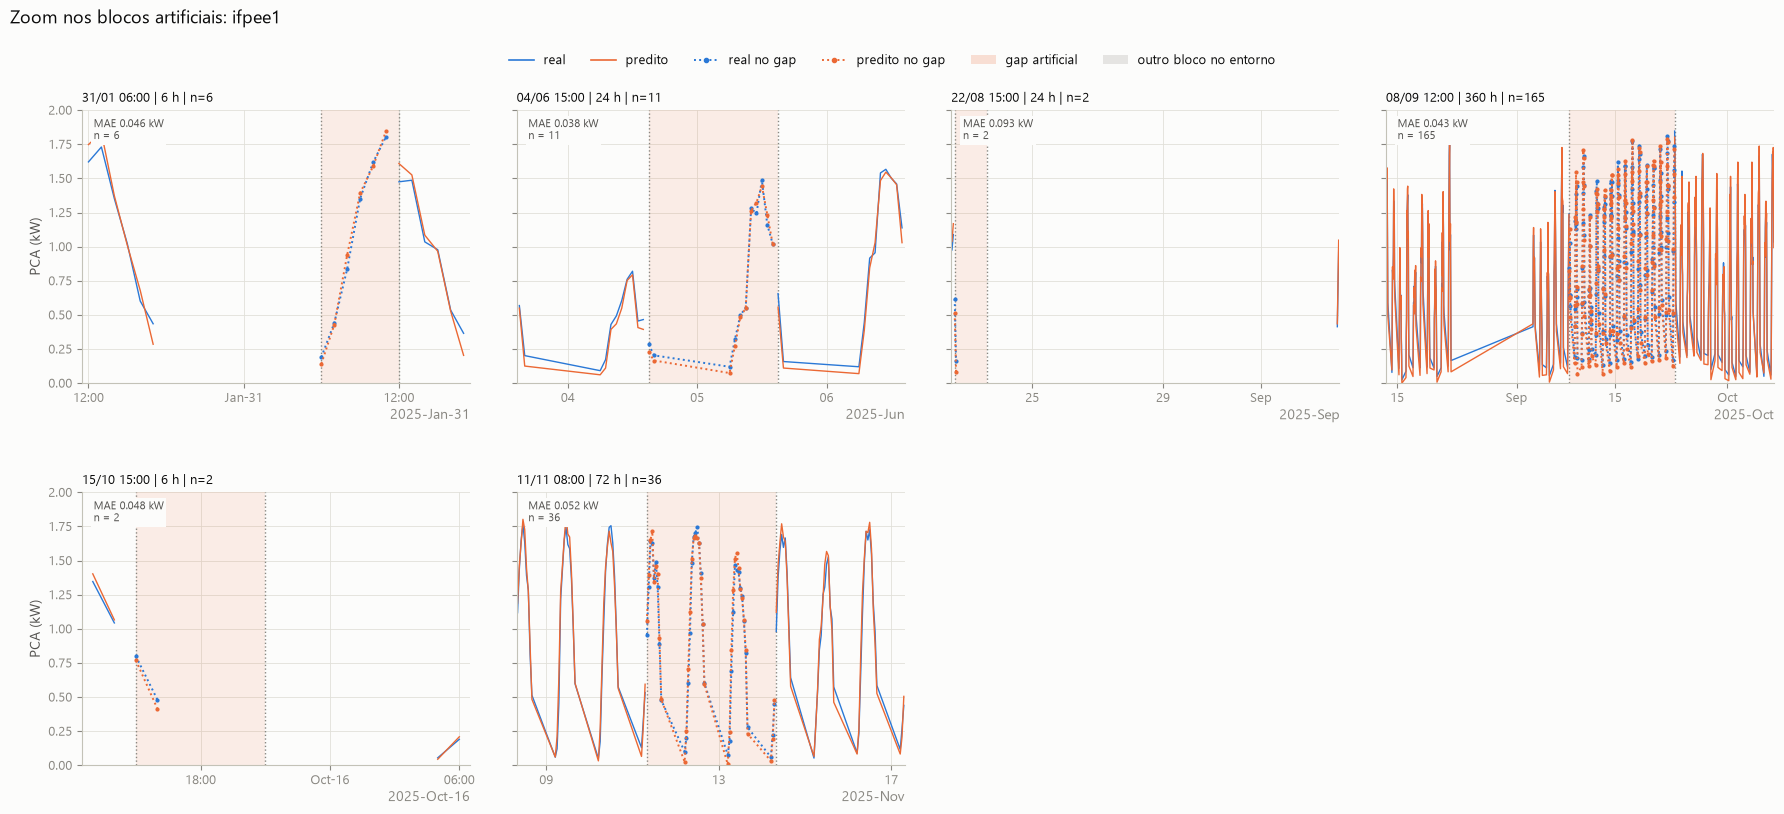

In [4]:
n_blocos = len(blocos_ifpee1)
ncols = 4
nrows = int(np.ceil(n_blocos / ncols))
fig, eixos = plt.subplots(
    nrows, ncols, figsize=(18, 4.0 * nrows + 0.4),
    sharey=True, squeeze=False)
eixos = eixos.ravel()

for ax, (_, b) in zip(eixos, blocos_ifpee1.iterrows()):
    k = int(b["bloco"])
    pos = np.flatnonzero(detalhe["bloco"].to_numpy() == k)
    n = len(pos)
    ini = max(0, pos[0] - n)
    fim = min(len(detalhe), pos[-1] + 1 + n)
    janela = detalhe.iloc[ini:fim]
    gap_local = (janela["bloco"].to_numpy() == k)
    foco = janela[gap_local]
    inicio, fim_prev = b["inicio"], b["fim_previsto"]

    # Outro bloco artificial que caia na janela, como o bloco 2 no
    # entorno do bloco 1, nao pode parecer dado normal.
    vizinhos = janela.loc[janela["gap"] & ~gap_local]
    for k_out in vizinhos["bloco"].unique():
        sub = vizinhos[vizinhos["bloco"] == k_out]
        ax.axvspan(sub["sample"].min() - pd.Timedelta(minutes=30),
                   sub["sample"].max() + pd.Timedelta(minutes=30),
                   color=plots.MUDO, alpha=0.12, lw=0)

    ax.axvspan(inicio, fim_prev, color=plots.PREDITO, alpha=0.10, lw=0)
    ax.axvline(inicio, color=plots.MUDO, ls=":", lw=1.0)
    ax.axvline(fim_prev, color=plots.MUDO, ls=":", lw=1.0)

    real_solido = janela["real"].where(~gap_local)
    pred_solido = janela["pred"].where(~gap_local)
    ax.plot(janela["sample"], real_solido, color=plots.REAL,
            lw=1.0, label="real")
    ax.plot(janela["sample"], pred_solido, color=plots.PREDITO,
            lw=1.0, label="predito")
    ax.plot(foco["sample"], foco["real"], color=plots.REAL, lw=1.4,
            ls=":", marker=".", ms=4, label="real no gap")
    ax.plot(foco["sample"], foco["pred"], color=plots.PREDITO, lw=1.4,
            ls=":", marker=".", ms=4, label="predito no gap")

    m = server.eval_metrics(foco)
    texto = f"MAE {m['mae']:.3f} kW\nn = {m['amostras']}"
    ax.text(0.03, 0.97, texto, transform=ax.transAxes, va="top",
            color=plots.TINTA_2, fontsize=8, bbox=plots.HALO)

    ax.set_ylim(0, LIMITE_KW)
    ax.set_xlim(janela["sample"].min() - pd.Timedelta(minutes=30),
                janela["sample"].max() + pd.Timedelta(minutes=30))
    plots.enfeitar(ax, "", "", "PCA (kW)")
    ax.set_title(f"{inicio:%d/%m %H:%M} | {b['duracao_h']:.0f} h | n={n}",
                 color=plots.TINTA, fontsize=9, loc="left", pad=6)
    loc = mdates.AutoDateLocator(minticks=3, maxticks=5)
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

for i, ax in enumerate(eixos[:n_blocos]):
    if i % ncols != 0:
        ax.set_ylabel("")
for ax in eixos[n_blocos:]:
    ax.set_visible(False)

handles = [
    plt.Line2D([], [], color=plots.REAL, lw=1.2, label="real"),
    plt.Line2D([], [], color=plots.PREDITO, lw=1.2, label="predito"),
    plt.Line2D([], [], color=plots.REAL, lw=1.4, ls=":", marker=".",
               label="real no gap"),
    plt.Line2D([], [], color=plots.PREDITO, lw=1.4, ls=":", marker=".",
               label="predito no gap"),
    Patch(facecolor=plots.PREDITO, alpha=0.20, edgecolor="none",
          label="gap artificial"),
    Patch(facecolor=plots.MUDO, alpha=0.20, edgecolor="none",
          label="outro bloco no entorno"),
]
fig.legend(handles=handles, loc="upper center", ncol=6, frameon=False,
           fontsize=9, labelcolor=plots.TINTA, bbox_to_anchor=(0.5, 0.94))
fig.suptitle(f"Zoom nos blocos artificiais: {INV_DETALHE}",
             x=0.01, ha="left", color=plots.TINTA, fontsize=13)
fig.subplots_adjust(top=0.86, bottom=0.08, left=0.05, right=0.99,
                    hspace=0.40, wspace=0.12)
plots.salvar_figura(fig, f"{PREFIXO}blocos_{INV_DETALHE}.png")
plt.show()

## 3. Desempenho geral do modelo embarcado

O conjunto válido exclui as linhas com `real` NaN, que são a sentinela de
`PCA == 0` do pré-processamento. A tabela separa o teste completo, as
amostras fora dos gaps e as amostras dentro dos gaps, para cada usina e
para o conjunto das três. O tempo de inferência é resumido sobre todas as
predições logadas; a média bruta é comparada com a média sem as primeiras
seis amostras de cada usina, que incluem o aquecimento do firmware.

  results\ensaio\analise_metricas.csv


         escopo inversor     n  MAE (kW)  RMSE (kW)     R²  viés (kW)  MAPE (%)  P90 (kW)  inferência média (µs)  inferência P90 (µs)
          total    todos 12117    0.0585     0.0765 0.9756     0.0145   12.2934    0.1246               991.9146                978.0
          total   ifpee1  4039    0.0549     0.0699 0.9801     0.0048   11.9605    0.1115               991.9243                978.0
          total   ifpee2  4039    0.0629     0.0844 0.9692     0.0291   12.8785    0.1405               991.9218                978.0
          total   ifpee3  4039    0.0577     0.0746 0.9772     0.0096   12.0410    0.1203               991.8976                978.0
  fora dos gaps    todos 11451    0.0589     0.0771 0.9752     0.0144   12.4686    0.1260               992.7580                978.0
  fora dos gaps   ifpee1  3817    0.0554     0.0705 0.9797     0.0048   12.1570    0.1124               992.7681                978.0
  fora dos gaps   ifpee2  3817    0.0632     0.0849 0.9688    

inversor     n  média geral (µs)  P90 geral (µs)  média sem aquecimento (µs)  P90 sem aquecimento (µs)  amostras descartadas
   todos 12126             991.9           978.0                       980.3                     978.0                    18
  ifpee1  4042             991.9           978.0                       980.4                     978.0                     6
  ifpee2  4042             991.9           978.0                       980.4                     978.0                     6
  ifpee3  4042             991.9           978.0                       980.3                     978.0                     6
  figura: results\figuras\analise_hexbin_total.png


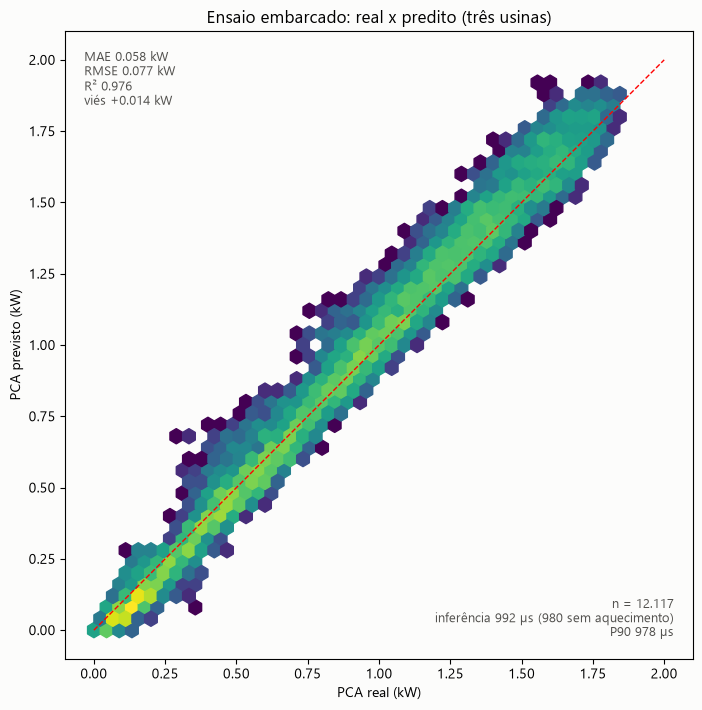

In [5]:
def linha_metricas(escopo, inversor, df):
    m = server.eval_metrics(df)
    return {
        "escopo": escopo,
        "inversor": inversor,
        "n": m["amostras"],
        "MAE (kW)": m["mae"],
        "RMSE (kW)": m["rmse"],
        "R²": m["r2"],
        "viés (kW)": m["vies"],
        "MAPE (%)": m["mape"],
        "P90 (kW)": m["p90"],
        "inferência média (µs)": m["inf_us_media"],
        "inferência P90 (µs)": m["inf_us_p90"],
    }

linhas = []
for escopo, sub in (("total", ensaio),
                    ("fora dos gaps", ensaio[~ensaio["gap"]]),
                    ("dentro dos gaps", ensaio[ensaio["gap"]])):
    linhas.append(linha_metricas(escopo, "todos", sub))
    for inv in INVERSORES:
        linhas.append(linha_metricas(
            escopo, inv, sub[sub["inversor"] == inv]))
metricas = pd.DataFrame(linhas)
salvar_csv(metricas, f"{PREFIXO}metricas", SUBPASTA)
print(metricas.round(4).to_string(index=False))

def resumo_inferencia(df):
    tempos = []
    for _, g in df.groupby("inversor"):
        s = pd.to_numeric(g.sort_values("sample")["inference_us"],
                          errors="coerce").dropna()
        tempos.append(s.iloc[AQUECIMENTO:])
    steady = pd.concat(tempos) if tempos else pd.Series(dtype=float)
    geral = pd.to_numeric(df["inference_us"], errors="coerce").dropna()
    return {
        "n": int(len(geral)),
        "média geral (µs)": float(geral.mean()),
        "P90 geral (µs)": float(geral.quantile(0.90)),
        "média sem aquecimento (µs)": float(steady.mean()),
        "P90 sem aquecimento (µs)": float(steady.quantile(0.90)),
        "amostras descartadas": int(AQUECIMENTO * df["inversor"].nunique()),
    }

inf_linhas = [{"inversor": "todos", **resumo_inferencia(ensaio)}]
for inv in INVERSORES:
    inf_linhas.append({
        "inversor": inv,
        **resumo_inferencia(ensaio[ensaio["inversor"] == inv])})
inferencia = pd.DataFrame(inf_linhas)
salvar_csv(inferencia, f"{PREFIXO}inferencia", SUBPASTA)
print(inferencia.round(1).to_string(index=False))

validos = ensaio.dropna(subset=["real", "pred"]).copy()
m_total = server.eval_metrics(validos)
inf_todos = inferencia.loc[inferencia["inversor"] == "todos"].iloc[0]

fig, ax = plt.subplots(figsize=(8.4, 7.2))
plots.hexbin_real_vs_pred(
    ax, validos["real"], validos["pred"],
    titulo="Ensaio embarcado: real x predito (três usinas)",
    extent=EXTENSO, gridsize=45)
texto = "\n".join([
    f"MAE {m_total['mae']:.3f} kW",
    f"RMSE {m_total['rmse']:.3f} kW",
    f"R² {m_total['r2']:.3f}",
    f"viés {m_total['vies']:+.3f} kW",
])
ax.text(0.03, 0.97, texto, transform=ax.transAxes, va="top",
        color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
texto_inf = "\n".join([
    f"n = {m_total['amostras']:,}".replace(",", "."),
    f"inferência {inf_todos['média geral (µs)']:.0f} µs "
    f"({inf_todos['média sem aquecimento (µs)']:.0f} sem aquecimento)",
    f"P90 {inf_todos['P90 geral (µs)']:.0f} µs",
])
ax.text(0.97, 0.03, texto_inf, transform=ax.transAxes, va="bottom",
        ha="right", color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
fig.tight_layout()
plots.salvar_figura(fig, f"{PREFIXO}hexbin_total.png")
plt.show()

## 4. Desempenho somente dentro dos gaps

O conjunto reúne as linhas com `gap=True` e `real` válido nas três usinas.
As durações menores e os blocos que caem sobre horários já ausentes na
série real têm poucas amostras, então o R² bruto de grupos pequenos pode
ficar negativo ou absurdo. A coluna `R² reportável` indica os grupos com
pelo menos 10 amostras e dispersão de `real` maior que zero; o valor bruto
fica no CSV para auditoria.

  results\ensaio\analise_gaps_duracao.csv


duração inversor  blocos   n  MAE (kW)  RMSE (kW)     R²  R² reportável  viés (kW)  MAPE (%)  P90 (kW)  inferência média (µs)  inferência P90 (µs)
    6 h    todos       2  24    0.0573     0.0710 0.9827           True     0.0197    9.0008    0.1212               977.4167                978.0
    6 h   ifpee1       2   8    0.0466     0.0533 0.9906          False    -0.0003    8.2589    0.0771               977.3750                978.0
    6 h   ifpee2       2   8    0.0697     0.0862 0.9731          False     0.0428    9.8992    0.1344               977.3750                978.0
    6 h   ifpee3       2   8    0.0557     0.0698 0.9834          False     0.0166    8.8444    0.1026               977.5000                978.0
   24 h    todos       2  39    0.0454     0.0560 0.9853           True    -0.0152   13.2390    0.0887               977.2821                978.0
   24 h   ifpee1       2  13    0.0467     0.0562 0.9854           True    -0.0230   13.7891    0.0821               9

inversor  bloco duração           início    fim observado   n  MAE (kW)  RMSE (kW)     R²  R² reportável  viés (kW)  MAPE (%)  P90 (kW)  inferência média (µs)  inferência P90 (µs)
   todos      1     6 h 2025-01-31 06:00 2025-01-31 11:00  18    0.0611     0.0764 0.9831           True     0.0416    9.1735    0.1294               977.3333                978.0
   todos      2    24 h 2025-06-04 15:00 2025-06-05 14:00  33    0.0374     0.0472 0.9901           True    -0.0017    9.6791    0.0815               977.1818                978.0
   todos      3    24 h 2025-08-22 15:00 2025-08-22 16:00   6    0.0896     0.0901 0.8359          False    -0.0896   32.8183    0.1034               977.8333                978.0
   todos      4    15 d 2025-09-08 12:00 2025-09-23 11:00 495    0.0484     0.0605 0.9834           True     0.0140    7.8378    0.1002               977.3919                978.0
   todos      5     6 h 2025-10-15 15:00 2025-10-15 16:00   6    0.0460     0.0516 0.8931          F

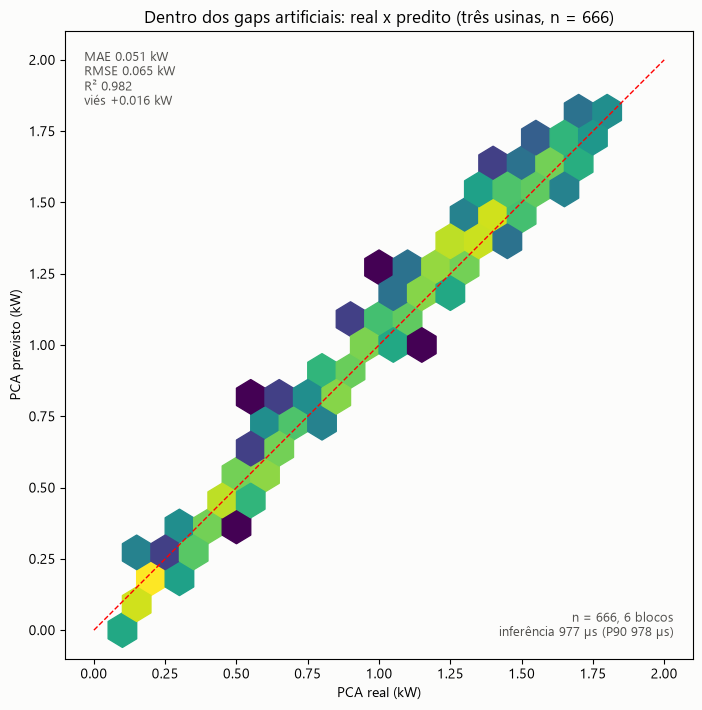

In [6]:
dentro = ensaio[ensaio["gap"]].dropna(subset=["real", "pred"]).copy()
if dentro.empty:
    raise ValueError("nao ha linhas em gaps com real valido")
m_dentro = server.eval_metrics(dentro)

DURACOES = sorted(dentro["gap_h"].unique())
ROTULO_DURACAO = {1.0: "1 h", 6.0: "6 h", 24.0: "24 h", 72.0: "3 d", 360.0: "15 d"}

def r2_reportavel(df):
    real = df["real"].dropna().to_numpy()
    return bool(len(real) >= 10 and np.ptp(real) > 0)

def linha_gap(duracao, inversor, df):
    m = server.eval_metrics(df)
    return {
        "duração": ROTULO_DURACAO.get(float(duracao), f"{duracao:g} h"),
        "inversor": inversor,
        "blocos": int(df["bloco"].nunique()),
        "n": m["amostras"],
        "MAE (kW)": m["mae"],
        "RMSE (kW)": m["rmse"],
        "R²": m["r2"],
        "R² reportável": r2_reportavel(df),
        "viés (kW)": m["vies"],
        "MAPE (%)": m["mape"],
        "P90 (kW)": m["p90"],
        "inferência média (µs)": m["inf_us_media"],
        "inferência P90 (µs)": m["inf_us_p90"],
    }

linhas = []
for h in DURACOES:
    sub_h = dentro[dentro["gap_h"].eq(h)]
    if sub_h.empty:
        continue
    linhas.append(linha_gap(h, "todos", sub_h))
    for inv in INVERSORES:
        sub = sub_h[sub_h["inversor"] == inv]
        if not sub.empty:
            linhas.append(linha_gap(h, inv, sub))
por_duracao = pd.DataFrame(linhas)
salvar_csv(por_duracao, f"{PREFIXO}gaps_duracao", SUBPASTA)
print(por_duracao.round(4).to_string(index=False))

linhas = []
for inv in ("todos", *INVERSORES):
    base = dentro if inv == "todos" else dentro[dentro["inversor"] == inv]
    for k in sorted(base["bloco"].unique()):
        sub = base[base["bloco"] == k]
        if sub.empty:
            continue
        m = server.eval_metrics(sub)
        linhas.append({
            "inversor": inv,
            "bloco": int(k),
            "duração": ROTULO_DURACAO.get(
                float(sub["gap_h"].iloc[0]),
                f"{sub['gap_h'].iloc[0]:g} h"),
            "início": sub["sample"].min().strftime("%Y-%m-%d %H:%M"),
            "fim observado": sub["sample"].max().strftime("%Y-%m-%d %H:%M"),
            "n": m["amostras"],
            "MAE (kW)": m["mae"],
            "RMSE (kW)": m["rmse"],
            "R²": m["r2"],
            "R² reportável": r2_reportavel(sub),
            "viés (kW)": m["vies"],
            "MAPE (%)": m["mape"],
            "P90 (kW)": m["p90"],
            "inferência média (µs)": m["inf_us_media"],
            "inferência P90 (µs)": m["inf_us_p90"],
        })
por_bloco = pd.DataFrame(linhas)
salvar_csv(por_bloco, f"{PREFIXO}gaps_blocos", SUBPASTA)
print(por_bloco.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.4, 7.2))
plots.hexbin_real_vs_pred(
    ax, dentro["real"], dentro["pred"],
    titulo=("Dentro dos gaps artificiais: real x predito "
            f"(três usinas, n = {len(dentro)})"),
    extent=EXTENSO, gridsize=20)
texto = "\n".join([
    f"MAE {m_dentro['mae']:.3f} kW",
    f"RMSE {m_dentro['rmse']:.3f} kW",
    f"R² {m_dentro['r2']:.3f}",
    f"viés {m_dentro['vies']:+.3f} kW",
])
ax.text(0.03, 0.97, texto, transform=ax.transAxes, va="top",
        color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
texto_inf = "\n".join([
    f"n = {m_dentro['amostras']}, {dentro['bloco'].nunique()} blocos",
    f"inferência {m_dentro['inf_us_media']:.0f} µs "
    f"(P90 {m_dentro['inf_us_p90']:.0f} µs)",
])
ax.text(0.97, 0.03, texto_inf, transform=ax.transAxes, va="bottom",
        ha="right", color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
fig.tight_layout()
plots.salvar_figura(fig, f"{PREFIXO}hexbin_gaps.png")
plt.show()

## Resumo e arquivos

In [7]:
cols_metricas = [
    "escopo", "inversor", "n", "MAE (kW)", "RMSE (kW)", "R²", "viés (kW)",
    "MAPE (%)", "P90 (kW)", "inferência média (µs)", "inferência P90 (µs)",
]
cols_duracao = [
    "duração", "inversor", "blocos", "n", "MAE (kW)", "RMSE (kW)", "R²",
    "R² reportável", "viés (kW)", "MAPE (%)", "P90 (kW)",
    "inferência média (µs)", "inferência P90 (µs)",
]
cols_blocos = [
    "inversor", "bloco", "duração", "início", "fim observado", "n",
    "MAE (kW)", "RMSE (kW)", "R²", "R² reportável", "viés (kW)",
]

total_todos = metricas[(metricas["inversor"] == "todos")
                       & (metricas["escopo"] == "total")].iloc[0]
fora_todos = metricas[(metricas["inversor"] == "todos")
                      & (metricas["escopo"] == "fora dos gaps")].iloc[0]
dentro_todos = metricas[(metricas["inversor"] == "todos")
                        & (metricas["escopo"] == "dentro dos gaps")].iloc[0]
ifpee1_dentro = metricas[(metricas["inversor"] == "ifpee1")
                         & (metricas["escopo"] == "dentro dos gaps")].iloc[0]
inf_todos = inferencia[inferencia["inversor"] == "todos"].iloc[0]
dur_todos = por_duracao[por_duracao["inversor"] == "todos"].copy()
dur_min = dur_todos.loc[dur_todos["MAE (kW)"].idxmin()]
dur_max = dur_todos.loc[dur_todos["MAE (kW)"].idxmax()]
maior_real = gaps_reais["horas"].max() if len(gaps_reais) else 0.0

saidas = [
    paths.FIGURAS / f"{PREFIXO}serie_{INV_DETALHE}.png",
    paths.FIGURAS / f"{PREFIXO}blocos_{INV_DETALHE}.png",
    paths.FIGURAS / f"{PREFIXO}hexbin_total.png",
    paths.FIGURAS / f"{PREFIXO}hexbin_gaps.png",
    paths.ENSAIO / f"{PREFIXO}gaps_reais.csv",
    paths.ENSAIO / f"{PREFIXO}metricas.csv",
    paths.ENSAIO / f"{PREFIXO}inferencia.csv",
    paths.ENSAIO / f"{PREFIXO}gaps_duracao.csv",
    paths.ENSAIO / f"{PREFIXO}gaps_blocos.csv",
    paths.RESULTS / f"{PREFIXO}final.md",
]

partes = [
    "# Análise final do ensaio embarcado",
    "",
    "Fonte: `results/ensaio/board_test.csv`, granularidade de 1 h, três "
    "usinas. Este documento reúne a análise completa do ensaio: série "
    "temporal, gaps, métricas gerais, desempenho dentro dos gaps e tempo de "
    "inferência.",
    "",
    "## Convenções",
    "",
    "- **gap artificial**: linha com `gap=True`, com duração de relógio "
    "conhecida. Os valores reais e preditos continuam no CSV e são usados na "
    "avaliação dentro dos gaps.",
    "- **gap real**: ausência de linha por mais de 16 h entre leituras "
    "consecutivas. O maior intervalo do teste é de 280 h.",
    "- **série temporal**: as linhas são mantidas contínuas na pausa noturna, "
    "em buracos menores que 6 h e nos blocos artificiais. Elas quebram em "
    "buracos reais de 6 h ou mais que não sejam a noite.",
    "- **tempo de inferência**: `inference_us`, medido no firmware ao redor "
    "de `runInference()` e gravado por amostra.",
    "",
    "## Inventário",
    "",
    f"- Linhas: {len(ensaio)} ({len(ensaio) // len(INVERSORES)} por usina).",
    f"- Linhas em gaps artificiais: {int(ensaio['gap'].sum())} "
    f"({ensaio['gap'].mean() * 100:.1f}%).",
    f"- Blocos artificiais por usina: {len(blocos_ifpee1)}.",
    f"- Gap real: {len(gaps_reais)} bloco(s); maior: {maior_real:.0f} h.",
    f"- Linhas com `real` NaN: {int(ensaio['real'].isna().sum())} "
    "(sentinela de PCA == 0, fora dos gaps).",
    "",
    "### Gaps reais",
    "",
    results.markdown_tabela(gaps_reais.round(2)),
    "",
    "## Série temporal",
    "",
    "A série completa usa somente `ifpee1`. O detalhe dos blocos artificiais "
    "fica na segunda figura; dentro deles, real e predito aparecem "
    "pontilhados.",
    "",
    "![Série completa](figuras/analise_serie_ifpee1.png)",
    "",
    "![Zoom nos blocos artificiais](figuras/analise_blocos_ifpee1.png)",
    "",
    "## Métricas gerais",
    "",
    "![Hexbin geral](figuras/analise_hexbin_total.png)",
    "",
    results.markdown_tabela(metricas[cols_metricas].round(4)),
    "",
    "## Métricas dentro dos gaps",
    "",
    "![Hexbin dentro dos gaps](figuras/analise_hexbin_gaps.png)",
    "",
    "### Por duração",
    "",
    results.markdown_tabela(por_duracao[cols_duracao].round(4)),
    "",
    "### Por bloco",
    "",
    results.markdown_tabela(por_bloco[cols_blocos].round(4)),
    "",
    "A coluna `R² reportável` é `False` quando o grupo tem menos de 10 "
    "amostras ou `real` sem dispersão. Nesses casos, o R² bruto fica no CSV, "
    "mas não deve ser citado.",
    "",
    "## Tempo de inferência",
    "",
    results.markdown_tabela(inferencia.round(1)),
    "",
    "## Síntese",
    "",
    f"- No teste completo, MAE de {total_todos['MAE (kW)']:.4f} kW e R² de "
    f"{total_todos['R²']:.4f}.",
    f"- Fora dos gaps, MAE de {fora_todos['MAE (kW)']:.4f} kW e R² de "
    f"{fora_todos['R²']:.4f}.",
    f"- Dentro dos gaps, MAE de {dentro_todos['MAE (kW)']:.4f} kW e R² de "
    f"{dentro_todos['R²']:.4f} nas três usinas; em ifpee1, MAE de "
    f"{ifpee1_dentro['MAE (kW)']:.4f} kW e R² de {ifpee1_dentro['R²']:.4f}.",
    f"- Entre as durações, o menor MAE agregado é o de {dur_min['duração']} "
    f"({dur_min['MAE (kW)']:.4f} kW) e o maior é o de {dur_max['duração']} "
    f"({dur_max['MAE (kW)']:.4f} kW).",
    f"- Inferência: média bruta de {inf_todos['média geral (µs)']:.1f} µs, "
    f"{inf_todos['média sem aquecimento (µs)']:.1f} µs sem aquecimento e P90 "
    f"de {inf_todos['P90 geral (µs)']:.1f} µs.",
    "",
    "## Arquivos",
    "",
    "### Figuras",
    "",
    "- `figuras/analise_serie_ifpee1.png`",
    "- `figuras/analise_blocos_ifpee1.png`",
    "- `figuras/analise_hexbin_total.png`",
    "- `figuras/analise_hexbin_gaps.png`",
    "",
    "### Tabelas (CSV)",
    "",
    "- `ensaio/analise_gaps_reais.csv`",
    "- `ensaio/analise_metricas.csv`",
    "- `ensaio/analise_inferencia.csv`",
    "- `ensaio/analise_gaps_duracao.csv`",
    "- `ensaio/analise_gaps_blocos.csv`",
    "",
    "## Ressalvas",
    "",
    "- A média bruta de inferência inclui as primeiras amostras de cada "
    "usina, que chegam a 1,5 a 11,8 ms.",
    "- O R² de grupos com menos de 10 amostras não é interpretável; a coluna "
    "`R² reportável` marca o que pode ser citado.",
    "- Blocos que caem sobre horários já ausentes na série real podem ter "
    "poucas leituras; a tabela por bloco mostra o n de cada um.",
    "- O ensaio é offline: o firmware recebe lotes do servidor em vez de ler "
    "sensores reais. Os gaps são artificiais e não validam falhas reais de "
    "telemetria.",
]
results.salvar_texto("\n".join(partes), f"{PREFIXO}final", "")

for p in saidas:
    if not (p.exists() and p.stat().st_size > 0):
        raise AssertionError(f"saida ausente ou vazia: {p}")
print(f"{len(saidas)} arquivos gerados em results/; relatório: "
      f"{saidas[-1].relative_to(paths.ROOT)}")

  results\analise_final.md


10 arquivos gerados em results/; relatório: results\analise_final.md


C:\Users\gusta\AppData\Local\Temp\ipykernel_5088\3514256116.py:75: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  results.markdown_tabela(gaps_reais.round(2)),
